# گام دوم پروژه: اسکریپت بارگذاری داده و آماده سازی محیط

**عنوان پروژه:** تشخیص اعداد دست نویس

**دانشجو:** رضا دهقانی

**هدف این گام:** دریافت مجموعه داده، بررسی ساختار اولیه آن، آماده کردن تصاویر و برچسب ها برای مراحل بعدی پروژه و ذخیره نسخه قابل استفاده از داده ها.

قبل از این گام منبع داده و مجوز استفاده از آن توسط اقای نجف زاده بررسی شده است. در این بخش تمرکز فقط روی بارگذاری داده و آماده سازی اولیه است. کد به صورت مرحله به مرحله نوشته شده تا اجرای آن و بررسی نتیجه ساده باشد.

**محیط اجرا:** Anaconda - jupyter

**منبع داده انتخاب شده:** مجموعه MADBase در وب سایت Hugging Face

## 1. آماده سازی کتابخانه ها

در این بخش کتابخانه های مورد نیاز را وارد می کنیم. کتابخانه `datasets` برای دریافت مجموعه داده، `numpy` برای کار با آرایه های عددی و `matplotlib` برای نمایش نمونه تصاویر استفاده می شود.

In [1]:
import sys
import subprocess
import importlib.util

if importlib.util.find_spec("datasets") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "datasets"])

import numpy as np
import matplotlib.pyplot as plt
from datasets import load_dataset

print("کتابخانه های مورد نیاز آماده هستند.")

کتابخانه های مورد نیاز آماده هستند.


## 2. دریافت مجموعه داده

در این مرحله مجموعه داده MADBase را بارگذاری می کنیم. پس از دریافت، نام بخش های موجود مانند داده های آموزش و آزمون نمایش داده می شود.

In [2]:
dataset_name = "MagedSaeed/MADBase"

try:
    dataset = load_dataset(dataset_name)
    print("مجموعه داده با موفقیت بارگذاری شد.")
    print(dataset)
except Exception as error:
    print("بارگذاری مجموعه داده انجام نشد.")
    raise error

مجموعه داده با موفقیت بارگذاری شد.
DatasetDict({
    train: Dataset({
        features: ['image', 'label'],
        num_rows: 59999
    })
    test: Dataset({
        features: ['image', 'label'],
        num_rows: 9999
    })
})


## 3. بررسی ساختار داده ها

در این بخش تعداد نمونه ها و نام ستون های هر بخش را بررسی می کنیم. این بررسی کمک می کند قبل از ادامه پروژه، از وجود ستون تصویر و برچسب مطمئن شویم.

In [3]:
for split_name, split_data in dataset.items():
    print(f"بخش: {split_name}")
    print(f"تعداد نمونه ها: {len(split_data)}")
    print(f"ستون ها: {split_data.column_names}")
    print("-" * 40)

بخش: train
تعداد نمونه ها: 59999
ستون ها: ['image', 'label']
----------------------------------------
بخش: test
تعداد نمونه ها: 9999
ستون ها: ['image', 'label']
----------------------------------------


## 4. تبدیل تصاویر و برچسب ها به آرایه

برای استفاده راحت تر در مراحل بعدی، تصاویر را به حالت خاکستری تبدیل می کنیم و در قالب آرایه های NumPy قرار می دهیم. برچسب هر تصویر نیز به صورت عددی نگهداری می شود.

In [4]:
prepared_data = {}

for split_name, split_data in dataset.items():
    if "image" not in split_data.column_names or "label" not in split_data.column_names:
        raise ValueError(
            f"ستون تصویر یا برچسب در بخش {split_name} پیدا نشد. "
            f"ستون های موجود: {split_data.column_names}"
        )

    images = []
    for image in split_data["image"]:
        # تبدیل تصویر به خاکستری و سپس آرایه عددی
        gray_image = image.convert("L")
        images.append(np.asarray(gray_image, dtype=np.uint8))

    images = np.stack(images)
    labels = np.asarray(split_data["label"], dtype=np.int64)

    if len(images) != len(labels):
        raise ValueError(f"تعداد تصاویر و برچسب ها در بخش {split_name} برابر نیست.")

    prepared_data[split_name] = {
        "images": images,
        "labels": labels
    }

    print(f"بخش {split_name}: ابعاد تصاویر = {images.shape}")
    print(f"بخش {split_name}: ابعاد برچسب ها = {labels.shape}")
    print(f"بخش {split_name}: نوع داده تصویر = {images.dtype}")
    print()

بخش train: ابعاد تصاویر = (59999, 28, 28)
بخش train: ابعاد برچسب ها = (59999,)
بخش train: نوع داده تصویر = uint8

بخش test: ابعاد تصاویر = (9999, 28, 28)
بخش test: ابعاد برچسب ها = (9999,)
بخش test: نوع داده تصویر = uint8



## 5. بررسی اولیه کیفیت داده

در این بخش چند مورد ساده را بررسی می کنیم: ابعاد تصاویر، کمترین و بیشترین مقدار پیکسل و تعداد برچسب های متفاوت. مقدار پیکسل در تصاویر خاکستری 8 بیتی معمولا بین 0 تا 255 است.

این مرحله فقط بررسی اولیه است و به معنی تایید کامل کیفیت یا مجوز داده ها نیست.

In [5]:
for split_name, split_data in prepared_data.items():
    images = split_data["images"]
    labels = split_data["labels"]

    print(f"بررسی بخش {split_name}")
    print("تعداد تصاویر:", len(images))
    print("ابعاد هر تصویر:", images.shape[1:])
    print("کمترین مقدار پیکسل:", int(images.min()))
    print("بیشترین مقدار پیکسل:", int(images.max()))
    print("برچسب های موجود:", np.unique(labels))
    print()

بررسی بخش train
تعداد تصاویر: 59999
ابعاد هر تصویر: (28, 28)
کمترین مقدار پیکسل: 0
بیشترین مقدار پیکسل: 255
برچسب های موجود: [0 1 2 3 4 5 6 7 8 9]

بررسی بخش test
تعداد تصاویر: 9999
ابعاد هر تصویر: (28, 28)
کمترین مقدار پیکسل: 0
بیشترین مقدار پیکسل: 255
برچسب های موجود: [0 1 2 3 4 5 6 7 8 9]



## 6. نمایش چند نمونه از تصاویر

برای اطمینان از اینکه تصاویر درست بارگذاری شده اند، چند نمونه را همراه با برچسب آنها نمایش می دهیم. این کار یک بررسی چشمی ساده است.

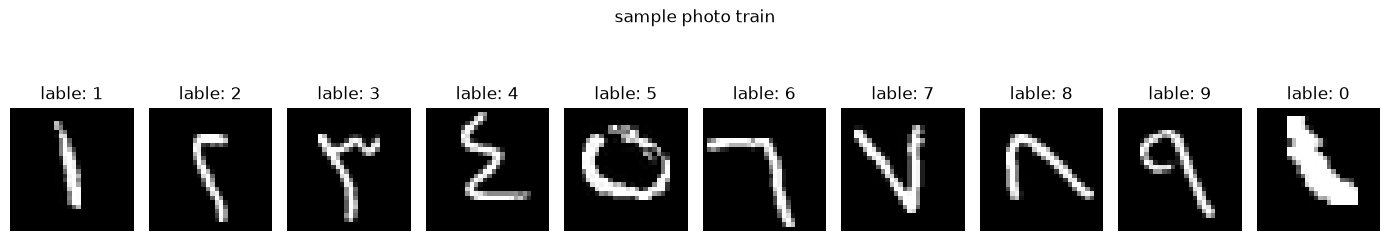

In [6]:
selected_split = "train" if "train" in prepared_data else next(iter(prepared_data))
images = prepared_data[selected_split]["images"]
labels = prepared_data[selected_split]["labels"]

show_count = min(10, len(images))
plt.figure(figsize=(14, 3))

for index in range(show_count):
    plt.subplot(1, show_count, index + 1)
    plt.imshow(images[index], cmap="gray")
    plt.title(f"lable: {labels[index]}")
    plt.axis("off")

plt.suptitle(f"sample photo {selected_split}")
plt.tight_layout()
plt.show()

## 7. ذخیره داده های آماده شده

در این مرحله تصاویر و برچسب ها را در یک فایل فشرده با پسوند `npz` ذخیره می کنیم تا در مراحل بعدی پروژه بتوانیم آنها را دوباره بارگذاری کنیم. نام فایل هر بخش مشخص می کند که داده مربوط به کدام قسمت است.

In [7]:
save_content = {}

for split_name, split_data in prepared_data.items():
    save_content[f"{split_name}_images"] = split_data["images"]
    save_content[f"{split_name}_labels"] = split_data["labels"]

file_name = "handwritten_digits_data.npz"
np.savez_compressed(file_name, **save_content)

print(f"داده های آماده شده در فایل {file_name} ذخیره شدند.")
print("کلیدهای ذخیره شده:", list(save_content.keys()))

داده های آماده شده در فایل handwritten_digits_data.npz ذخیره شدند.
کلیدهای ذخیره شده: ['train_images', 'train_labels', 'test_images', 'test_labels']


## 8. نتیجه گیری این گام

در این گام، محیط اولیه آماده شد، مجموعه داده دریافت شد، تصاویر به حالت خاکستری و آرایه های عددی تبدیل شدند، برچسب ها بررسی شدند و چند نمونه تصویر نمایش داده شد. در پایان نیز داده ها برای استفاده مجدد ذخیره شدند.

**خروجی این گام:** فایل `handwritten_digits_data.npz` شامل تصاویر و برچسب های بخش های موجود در مجموعه داده است.

در گام بعدی می توان از داده های آماده شده برای پیش پردازش تکمیلی، تقسیم بندی مناسب داده ها و ساخت مدل تشخیص اعداد دست نویس استفاده کرد.

**نکته:** این کد مدل یادگیری ماشین آموزش نمی دهد و دقت تشخیص را محاسبه نمی کند؛ هدف آن فقط بارگذاری و آماده سازی اولیه داده ها است.